In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.metrics import accuracy_score, classification_report
from collections import Counter, defaultdict
from datasets import load_dataset
import random
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('dark_background')
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: cpu
PyTorch version: 2.11.0+cpu


## Many-to-One (SMS Spam Classification) - PRACTICE

In [3]:
from datasets import load_dataset

print('Loading SMS Spam dataset...')

sms_data = load_dataset('ucirvine/sms_spam', split='train')
# Shuffle and split
sms_data = sms_data.shuffle(seed=42)
split_idx = int(0.8 * len(sms_data))

train_sms = sms_data.select(range(split_idx))
test_sms = sms_data.select(range(split_idx, len(sms_data)))

print(f'\nDataset: SMS Spam Collection')
print(f'Train: {len(train_sms)} messages')
print(f'Test: {len(test_sms)} messages')
print(f'\nClasses: 0=Not Spam, 1=Spam')

print(f'\nSample messages:')
print(f'Message: {train_sms[0]["sms"]}')
print(f'Label: {train_sms[0]["label"]}')
print(f'\nMessage: {train_sms[10]["sms"]}')
print(f'Label: {train_sms[10]["label"]}')

Loading SMS Spam dataset...


README.md:   0%|          | 0.00/4.98k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  359kB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5574 [00:00<?, ? examples/s]


Dataset: SMS Spam Collection
Train: 4459 messages
Test: 1115 messages

Classes: 0=Not Spam, 1=Spam

Sample messages:
Message: sports fans - get the latest sports news str* 2 ur mobile 1 wk FREE PLUS a FREE TONE Txt SPORT ON to 8007 www.getzed.co.uk 0870141701216+ norm 4txt/120p 

Label: 1

Message: Cramps stopped. Going back to sleep

Label: 0


##TODO 1: Build Vocabulary for SMS Data


In [4]:
sms_vocab = {'<PAD>': 0, '<UNK>': 1}
sms_word_counts = Counter()

for item in train_sms:
    words = item['sms'].lower().split()
    sms_word_counts.update(words)

for word, count in sms_word_counts.items():
    if count >= 2 and word not in sms_vocab:
        sms_vocab[word] = len(sms_vocab)

print(f'SMS Vocabulary size: {len(sms_vocab)}')
print(f'Sample vocab: {list(sms_vocab.items())[:10]}')

SMS Vocabulary size: 4754
Sample vocab: [('<PAD>', 0), ('<UNK>', 1), ('sports', 2), ('-', 3), ('get', 4), ('the', 5), ('latest', 6), ('news', 7), ('2', 8), ('ur', 9)]


In [6]:
EMBEDDING_DIM = 100
glove_vectors = {}

# Create SMS embedding matrix (using same GloVe vectors)
sms_embedding_matrix = np.random.randn(len(sms_vocab), EMBEDDING_DIM).astype('float32') * 0.01
sms_embedding_matrix[sms_vocab['<PAD>']] = np.zeros(EMBEDDING_DIM)
found_count_sms = 0
for word, idx in sms_vocab.items():
    if word in glove_vectors:
        sms_embedding_matrix[idx] = glove_vectors[word]
        found_count_sms += 1

print(f'SMS Embedding matrix shape: {sms_embedding_matrix.shape}')
print(f'Found GloVe vectors for {found_count_sms}/{len(sms_vocab)} words ({100*found_count_sms/len(sms_vocab):.1f}%)')

SMS Embedding matrix shape: (4754, 100)
Found GloVe vectors for 0/4754 words (0.0%)


##TODO 2: Create SpamDataset Class

In [8]:
class SpamDataset(Dataset):
    """Dataset for SMS Spam classification (Many-to-One)"""

    def __init__(self, data, vocab):
        self.data = data
        self.vocab = vocab

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        words = item['sms'].lower().split()

        if not words:
            words = ['<UNK>']

        word_ids = [self.vocab.get(word, self.vocab['<UNK>']) for word in words]
        label = item['label']

        return torch.tensor(word_ids, dtype=torch.long), torch.tensor(label, dtype=torch.long)

def spam_collate_fn(batch):
    texts, labels = zip(*batch)
    lengths = torch.tensor([len(t) for t in texts])
    padded_texts = pad_sequence(texts, batch_first=True, padding_value=sms_vocab['<PAD>'])
    labels = torch.tensor(labels, dtype=torch.long)
    return padded_texts, labels, lengths


# Create datasets
train_spam_dataset = SpamDataset(train_sms, sms_vocab)
test_spam_dataset = SpamDataset(test_sms, sms_vocab)

train_spam_loader = DataLoader(train_spam_dataset, batch_size=32, shuffle=True, collate_fn=spam_collate_fn)
test_spam_loader = DataLoader(test_spam_dataset, batch_size=32, shuffle=False, collate_fn=spam_collate_fn)

print(f'Train batches: {len(train_spam_loader)}')
print(f'Test batches: {len(test_spam_loader)}')

Train batches: 140
Test batches: 35


## TODO 3: Implement 4 RNN Models for Spam Classification


In [9]:
from torch.nn.utils.rnn import pack_padded_sequence

# 1. Vanilla RNN
class VanillaRNNSpam(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, embedding_matrix):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix))
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)
        final_hidden = hidden[-1]
        return self.fc(final_hidden)


# 2. GRU
class GRUSpam(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, embedding_matrix):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix))
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        final_hidden = hidden[-1]
        return self.fc(final_hidden)


# 3. LSTM
class LSTMSpam(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, embedding_matrix):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix))
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        final_hidden = hidden[-1]
        return self.fc(final_hidden)


# 4. BiLSTM
class BiLSTMSpam(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, embedding_matrix):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix))
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, 2)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)

        final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(final_hidden)


print('All 4 spam classification models defined!')

All 4 spam classification models defined!


In [10]:
def train_spam_model(model, train_loader, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for texts, labels, lengths in train_loader:
            texts, labels = texts.to(device), labels.to(device)
            optimizer.zero_grad()
            predictions = model(texts, lengths)
            loss = criterion(predictions, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}')
    return losses


def evaluate_spam_model(model, test_loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for texts, labels, lengths in test_loader:
            texts = texts.to(device)
            predictions = model(texts, lengths)
            predicted_labels = torch.argmax(predictions, dim=1).cpu().numpy()
            all_preds.extend(predicted_labels)
            all_labels.extend(labels.numpy())
    accuracy = accuracy_score(all_labels, all_preds)
    return accuracy


print('Training functions ready!')

Training functions ready!


In [13]:
# Train all 4 spam models
SPAM_HIDDEN_DIM = 128
SPAM_EPOCHS = 10
SPAM_LR = 0.001

spam_results = {}

# Vanilla RNN
print('='*60)
print('Training Vanilla RNN for Spam...')
print('='*60)
rnn_spam = VanillaRNNSpam(len(sms_vocab), EMBEDDING_DIM, SPAM_HIDDEN_DIM, sms_embedding_matrix)
rnn_spam_losses = train_spam_model(rnn_spam, train_spam_loader, epochs=SPAM_EPOCHS, lr=SPAM_LR)
rnn_spam_acc = evaluate_spam_model(rnn_spam, test_spam_loader)
spam_results['Vanilla RNN'] = {'losses': rnn_spam_losses, 'accuracy': rnn_spam_acc}
print(f'\nVanilla RNN Spam Accuracy: {rnn_spam_acc:.4f}\n')

# GRU
print('='*60)
print('Training GRU for Spam...')
print('='*60)
gru_spam = GRUSpam(len(sms_vocab), EMBEDDING_DIM, SPAM_HIDDEN_DIM, sms_embedding_matrix)
gru_spam_losses = train_spam_model(gru_spam, train_spam_loader, epochs=SPAM_EPOCHS, lr=SPAM_LR)
gru_spam_acc = evaluate_spam_model(gru_spam, test_spam_loader)
spam_results['GRU'] = {'losses': gru_spam_losses, 'accuracy': gru_spam_acc}
print(f'\nGRU Spam Accuracy: {gru_spam_acc:.4f}\n')

# LSTM
print('='*60)
print('Training LSTM for Spam...')
print('='*60)
lstm_spam = LSTMSpam(len(sms_vocab), EMBEDDING_DIM, SPAM_HIDDEN_DIM, sms_embedding_matrix)
lstm_spam_losses = train_spam_model(lstm_spam, train_spam_loader, epochs=SPAM_EPOCHS, lr=SPAM_LR)
lstm_spam_acc = evaluate_spam_model(lstm_spam, test_spam_loader)
spam_results['LSTM'] = {'losses': lstm_spam_losses, 'accuracy': lstm_spam_acc}
print(f'\nLSTM Spam Accuracy: {lstm_spam_acc:.4f}\n')

# BiLSTM
print('='*60)
print('Training BiLSTM for Spam...')
print('='*60)
bilstm_spam = BiLSTMSpam(len(sms_vocab), EMBEDDING_DIM, SPAM_HIDDEN_DIM, sms_embedding_matrix)
bilstm_spam_losses = train_spam_model(bilstm_spam, train_spam_loader, epochs=SPAM_EPOCHS, lr=SPAM_LR)
bilstm_spam_acc = evaluate_spam_model(bilstm_spam, test_spam_loader)
spam_results['BiLSTM'] = {'losses': bilstm_spam_losses, 'accuracy': bilstm_spam_acc}
print(f'\nBiLSTM Spam Accuracy: {bilstm_spam_acc:.4f}\n')

Training Vanilla RNN for Spam...
Epoch 1/10, Loss: 0.2405
Epoch 2/10, Loss: 0.0540
Epoch 3/10, Loss: 0.0211
Epoch 4/10, Loss: 0.0130
Epoch 5/10, Loss: 0.0107
Epoch 6/10, Loss: 0.0075
Epoch 7/10, Loss: 0.0048
Epoch 8/10, Loss: 0.0034
Epoch 9/10, Loss: 0.0028
Epoch 10/10, Loss: 0.0052

Vanilla RNN Spam Accuracy: 0.9776

Training GRU for Spam...
Epoch 1/10, Loss: 0.2286
Epoch 2/10, Loss: 0.0387
Epoch 3/10, Loss: 0.0160
Epoch 4/10, Loss: 0.0109
Epoch 5/10, Loss: 0.0061
Epoch 6/10, Loss: 0.0034
Epoch 7/10, Loss: 0.0016
Epoch 8/10, Loss: 0.0014
Epoch 9/10, Loss: 0.0012
Epoch 10/10, Loss: 0.0012

GRU Spam Accuracy: 0.9821

Training LSTM for Spam...
Epoch 1/10, Loss: 0.2455
Epoch 2/10, Loss: 0.0459
Epoch 3/10, Loss: 0.0245
Epoch 4/10, Loss: 0.0139
Epoch 5/10, Loss: 0.0097
Epoch 6/10, Loss: 0.0076
Epoch 7/10, Loss: 0.0038
Epoch 8/10, Loss: 0.0022
Epoch 9/10, Loss: 0.0014
Epoch 10/10, Loss: 0.0012

LSTM Spam Accuracy: 0.9794

Training BiLSTM for Spam...
Epoch 1/10, Loss: 0.2449
Epoch 2/10, Loss:

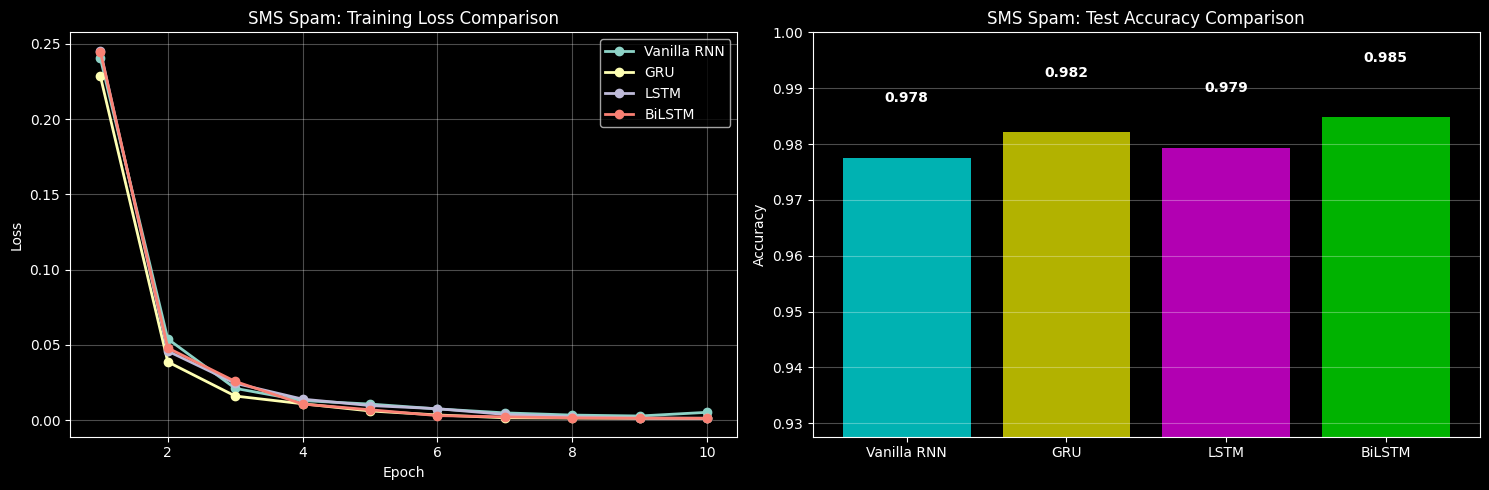

SMS SPAM RESULTS SUMMARY
Vanilla RNN     Accuracy: 0.9776
GRU             Accuracy: 0.9821
LSTM            Accuracy: 0.9794
BiLSTM          Accuracy: 0.9848


In [14]:
# Visualize spam results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Training losses
for name, data in spam_results.items():
    ax1.plot(range(1, SPAM_EPOCHS+1), data['losses'], marker='o', label=name, linewidth=2)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('SMS Spam: Training Loss Comparison')
ax1.legend()
ax1.grid(alpha=0.3)

# Test accuracies
models = list(spam_results.keys())
accuracies = [spam_results[m]['accuracy'] for m in models]
colors = ['cyan', 'yellow', 'magenta', 'lime']
ax2.bar(models, accuracies, color=colors, alpha=0.7)
ax2.set_ylabel('Accuracy')
ax2.set_title('SMS Spam: Test Accuracy Comparison')
ax2.set_ylim([min(accuracies) - 0.05, 1.0])
ax2.grid(alpha=0.3, axis='y')
for i, v in enumerate(accuracies):
    ax2.text(i, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print('='*60)
print('SMS SPAM RESULTS SUMMARY')
print('='*60)
for name, data in spam_results.items():
    print(f"{name:15s} Accuracy: {data['accuracy']:.4f}")
print('='*60)